# RRFS plots of 850 hPa temp/heights/vectors and 500 hPa Absolute vorticity/Heights/Wind vectors from the 13 km North American data

## These reproduce some of the plots that are available on the UW Madison AOS web site at https://www.aos.wisc.edu/weather/wx_models/rrfs_na_13km_12UTC.shtml
- Pete Pokrandt / UW-Madison AOS / October, 2026

In [1]:
# Import common modules

# Cartopy, matplotlib, xarray, netcdf, numpy, sys
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import xarray as xr
from netCDF4 import num2date
import numpy as np
import sys

#Import metpy functions, etc
import metpy.calc as mpcalc
from metpy.plots import add_metpy_logo, add_timestamp, scattertext
from metpy.units import units
from metpy.calc import lat_lon_grid_deltas, find_peaks

# Some date/time functions
from datetime import date, datetime, timedelta, tzinfo, timezone
from time import sleep, perf_counter, localtime

# Matplotlib Path effects to make titles easier to read
from matplotlib import patheffects
outline_effect = [patheffects.withStroke(linewidth=2, foreground='black')]


#matplotlib.use('Agg')
#Set matplotlib magic inline plotting
%matplotlib inline


## Define some color tables for the shading - these match the old plots that we used to make with wxp back in the day...

In [2]:
# I created color tables for various variables to mimic the original plots for NAM/GFS/etc made with wxp.

def colors_levels(levelname):
    """For a given string levelname, return lists of levels, colors"""
    if levelname == "850temps":
        levels=range(-40,42,2)
        colors=[(0.5 , 0.8 , 0. ),\
                (0.8 , 0.9 , 0. ),\
                (1.  , 1.  , 0. ),\
                (1.  , 0.8 , 0. ),\
                (1.  , 0.6 , 0. ),\
                (1.  , 0.4 , 0. ),\
                (1.  , 0.  , 0. ),\
                (0.8 , 0.  , 0. ),\
                (0.6 , 0.  , 0. ),\
                (0.4 , 0.  , 0.0 ),\
                (0.4 , 0.  , 0.4 ),\
                (0.6 , 0.  , 0.6 ),\
                (0.8 , 0.  , 0.8 ),\
                (1.  , 0.  ,  1. ),\
                (0.75, 0.  ,  1. ),\
                (0.5 , 0.  ,  1. ),\
                (0.  , 0.  ,  1. ),\
                (0.  , 0.35,  1. ),\
                (0.  , 0.55,  1. ),\
                (0.  , 0.75,  1. ),\
                (0.  , 1.  ,  1. ),\
                (0.  , 0.9 , 0.8 ),\
                (0.  , 0.8 , 0.5 ),\
                (0.  , 0.7 , 0. ),\
                (0.5 , 0.8 , 0. ),\
                (0.8 , 0.9 , 0. ),\
                (1.  , 1.  , 0. ),\
                (1.  , 0.8 , 0. ),\
                (1.  , 0.6 , 0. ),\
                (1.  , 0.4 , 0. ),\
                (1.  , 0.  , 0. ),\
                (0.8 , 0.  , 0. ),\
                (0.6 , 0.  , 0. ),\
                (0.4 , 0.  , 0.0 ),\
                (0.4 , 0.  , 0.4 ),\
                (0.6 , 0.  , 0.6 ),\
                (0.8 , 0.  , 0.8 ),\
                (1.  , 0.  ,  1. ),\
                (0.75, 0.  ,  1. ),\
                (0.5 , 0.  ,  1. )]
    elif levelname == "850heights":
        levels=range(750,1830,30)
        colors="white" 
    elif levelname == "500vort":
        levels = range(-10,52,2)
        colors = [(0.4,  0.,   0.4 ),\
                (0.6 , 0.  , 0.6 ),\
                (0.8 , 0.  , 0.8 ),\
                (1.  , 0.  ,  1. ),\
                (0.75, 0.  ,  1. ),\
                (0.5 , 0.  ,  1. ),\
                (0.  , 0.  ,  1. ),\
                (0.  , 0.35,  1. ),\
                (0.  , 0.55,  1. ),\
                (0.  , 0.75,  1. ),\
                (0.  , 1.  ,  1. ),\
                (0.  , 0.9 , 0.8 ),\
                (0.  , 0.8 , 0.5 ),\
                (0.  , 0.7 , 0. ),\
                (0.5 , 0.8 , 0. ),\
                (0.8 , 0.9 , 0. ),\
                (1.  , 1.  , 0. ),\
                (1.  , 0.8 , 0. ),\
                (1.  , 0.6 , 0. ),\
                (1.  , 0.4 , 0. ),\
                (1.  , 0.  , 0. ),\
                (0.8 , 0.  , 0. ),\
                (0.6 , 0.  , 0. ),\
                (0.4 , 0.  , 0.0 ),\
                (0.4 , 0.  , 0.4 ),\
                (0.6 , 0.  , 0.6 ),\
                (0.8 , 0.  , 0.8 ),\
                (1.  , 0.  ,  1. ),\
                (0.75, 0.  ,  1. ),\
                (0.5 , 0.  ,  1. ),\
                (0.  , 0.  ,  1. ),\
                (0.  , 0.35,  1. ),\
                (0.  , 0.55,  1. ),\
                (0.  , 0.75,  1. ),\
                (0.  , 1.  ,  1. )]
    elif levelname == "500heights":
        levels=range(4500,6300,60)
        colors="white"
    else:
        print("BAD levelname:",levelname)
        quit()
    return levels, colors


## Let's plot data for 12 UTC today. Figure out what day it is and set some variables

In [3]:
# figure out what time/day it is

today = datetime.now(timezone.utc)
print("today is ",today)
#today = datetime(2019,12,4,12,00,00)
print ("first argument is ",sys.argv[1])
# Lets plot today's 12 UTC run. Can change to 00/06/18 for other model initialization times
#sinithour = "00"
sinithour= "12"
inithour = int(sinithour)

# if you are running as a script and want to specify the model initialization hour as an argument on the command line, you can do it with these two lines
#sinithour = sys.argv[1]
#inithour = int(sys.argv[1])

print("inithour = ",inithour)
print("sinithour = ",sinithour)

year = int(today.strftime("%Y"))
month = int(today.strftime("%m"))
day = int(today.strftime("%d"))
#year = int(today.strftime("%Y"))
#month = int(today.strftime("%m"))
#day = int(today.strftime("%d"))

modelinit = datetime(year, month, day, inithour)

print("modelinit",modelinit)

# Get some string versions of the year/month/day and two character model initialization time to use below when creating the file name
syear = today.strftime("%Y")
smonth = today.strftime("%m")
sday = today.strftime("%d")
sinithour = str(inithour)
if (sinithour == "0"):
    sinithour = "00"
elif (sinithour == "6"):
    sinithour = "06"

print ("year, month, day ",year, month, day)
print ("syear, smonth, sday ",syear, smonth, sday)

# define some geographic boundaries for later
# Canadian Provinces
provinc_bodr = cfeature.NaturalEarthFeature(category='cultural',
    name='admin_1_states_provinces_lines', scale='50m', facecolor='none', edgecolor='k')

# Lakes
lakes = cfeature.NaturalEarthFeature('physical', 'lakes', \
    scale='50m', edgecolor='b', facecolor='none')


today is  2026-11-03 18:14:38.214334+00:00
first argument is  -f
inithour =  12
sinithour =  12
modelinit 2026-11-03 12:00:00
year, month, day  2026 11 3
syear, smonth, sday  2026 11 03


## We are using data from the UW-AOS THREDDS server at https://thredds.aos.wisc.edu/thredds/catalog/grib/NCEP/RRFS/CONUS_13km/catalog.html

## which is a subset of what is available at https://nomads.ncep.noaa.gov/pub/data/nccf/com/rrfs/para 
### (will change from para to prod starting with the 12 UTC Nov 3 2026 run)

### Data on nomads is hourly forecasts, but I am only pulling 3 hourly forecasts for now.

In [4]:
# specify the data set and open as an xarray dataset
xr_dsname ="https://thredds.aos.wisc.edu/thredds/dodsC/grib/NCEP/RRFS/CONUS_13km/RRFS_CONUS_13km_"+syear+smonth+sday+"_"+sinithour+"00.grib2"
XR_DS = xr.open_dataset(xr_dsname)

In [5]:
# Print out basic information about the data set - commented out here but 
# uncomment and run this cell to get more info about what's in the data set

#print("XR_DS ",XR_DS)

In [6]:
# It's in a rotated lat/lon projection. Let's take a look at what that looks like
print("XR_DS.RotatedLatLon_Projection ",XR_DS.RotatedLatLon_Projection)

# cartopy supports rotated lat/lon projections. Get the projection info from the Xarray data set.
# We will be plotting on the native rotated lat/lon projection.
crs_rotated = ccrs.RotatedPole(XR_DS.RotatedLatLon_Projection.grid_north_pole_longitude, XR_DS.RotatedLatLon_Projection.grid_north_pole_latitude)

XR_DS.RotatedLatLon_Projection  <xarray.DataArray 'RotatedLatLon_Projection' ()> Size: 4B
[1 values with dtype=int32]
Coordinates:
    reftime  datetime64[ns] 8B ...
Attributes:
    grid_mapping_name:          rotated_latitude_longitude
    grid_north_pole_latitude:   35.0
    grid_north_pole_longitude:  67.0
    _CoordinateTransformType:   Projection
    _CoordinateAxisTypes:       GeoX GeoY


In [7]:
# let's plot a 24 hour forecast
hour = 24 

# convert to a 3 digit string - used in the plot title later
if(hour < 10):
    shour = "00"+str(hour)
elif(hour < 100):
    shour = "0"+str(hour)
else:
    shour = str(hour)

ftime = modelinit + timedelta(hours=hour)
fyear = ftime.strftime("%Y")
fmonth = ftime.strftime("%m")
fmonth_name = ftime.strftime("%b")
fday = ftime.strftime("%d")
fday_name = ftime.strftime("%a")
fhour = ftime.strftime("%H")

# Since I have forecast hours starting at 0h and then every 3h out to 84h, I need to convert the forecast hour
# into an index into the time dimension of the arrays
xr_wantedtime = int((hour/3))

# 850 hPa heights, temperature, wind vectors

In [8]:
# Specify that we want to use data at 850 hPa (85000 Pa)
temp_pres_val=85000.0
hght_pres_val=85000.0
u_pres_val=85000.0
v_pres_val=85000.0

# Grab the dimension variables for each of the variables that we want to plot
temp_kwdim=XR_DS['Temperature_isobaric'].dims
hght_kwdim=XR_DS['Geopotential_height_isobaric'].dims
u_kwdim=XR_DS['u-component_of_wind_isobaric'].dims
v_kwdim=XR_DS['v-component_of_wind_isobaric'].dims

# Figure out what time and height (isobaric) keyword each variable is using. Turns out they are all the same in this case, but
# sometimes different variables use different names for these dimensions because they have different time intervals or
# different vertical coordinate systems or pressure levels.
xr_temp_da_time_keyword = str(temp_kwdim[0])
xr_hght_da_time_keyword = str(hght_kwdim[0])
xr_u_da_time_keyword = str(u_kwdim[0])
xr_v_da_time_keyword = str(v_kwdim[0])
xr_temp_da_isobaric_keyword = str(temp_kwdim[1])
xr_hght_da_isobaric_keyword = str(hght_kwdim[1])
xr_u_da_isobaric_keyword = str(u_kwdim[1])
xr_v_da_isobaric_keyword = str(v_kwdim[1])

# print out an example of what these are
print("xr_temp_da_time_keyword = ",xr_temp_da_time_keyword)
print("xr_temp_da_isobaric_keyword = ",xr_temp_da_isobaric_keyword)

# Figure out the index in the vertical direction for the level that we want.
temp_pres_index=np.where(XR_DS[xr_temp_da_isobaric_keyword].values == temp_pres_val)[0]
hght_pres_index=np.where(XR_DS[xr_hght_da_isobaric_keyword].values == hght_pres_val)[0]
u_pres_index=np.where(XR_DS[xr_u_da_isobaric_keyword].values == u_pres_val)[0]
v_pres_index=np.where(XR_DS[xr_v_da_isobaric_keyword].values == v_pres_val)[0]

print("temp_pres_index = ",temp_pres_index)

# Pull in data arrays for each variable at the time and level that we want. Thin out the u/v components of the wind so there aren't so many wind vectors
xr_temp_da = XR_DS.Temperature_isobaric.isel({xr_temp_da_time_keyword:xr_wantedtime}).isel({xr_temp_da_isobaric_keyword:temp_pres_index})
xr_hght_da = XR_DS.Geopotential_height_isobaric.isel({xr_hght_da_time_keyword:xr_wantedtime}).isel({xr_hght_da_isobaric_keyword:hght_pres_index})
xr_u_da = XR_DS["u-component_of_wind_isobaric"].isel({xr_u_da_time_keyword:xr_wantedtime}).isel({xr_u_da_isobaric_keyword:u_pres_index}).thin(20)
xr_v_da = XR_DS["v-component_of_wind_isobaric"].isel({xr_v_da_time_keyword:xr_wantedtime}).isel({xr_v_da_isobaric_keyword:v_pres_index}).thin(20)

# Grab the lat/lon values in the rotated coordinate system. Again, thin out the lat/lon for the vector components.
rlat=XR_DS.rlat
rlon=XR_DS.rlon
rlonvec=XR_DS.rlon.thin(20)
rlatvec=XR_DS.rlat.thin(20)


xr_temp_da_time_keyword =  time2
xr_temp_da_isobaric_keyword =  isobaric1
temp_pres_index =  [38]


In [9]:
# Read in the actual data values. Convert temperatures from kelvin to celsius, 
# winds from m/s to knots. Heights are in meters.
# * note * I am bad, I'm not using the units included in the data. 
# It just worked out that way with the way I was plotting data.. Sorry..

temperatures = xr_temp_da.values[0]-273.15
heights = xr_hght_da.values[0]
u = xr_u_da.values[0]*1.94384
v = xr_v_da.values[0]*1.94384


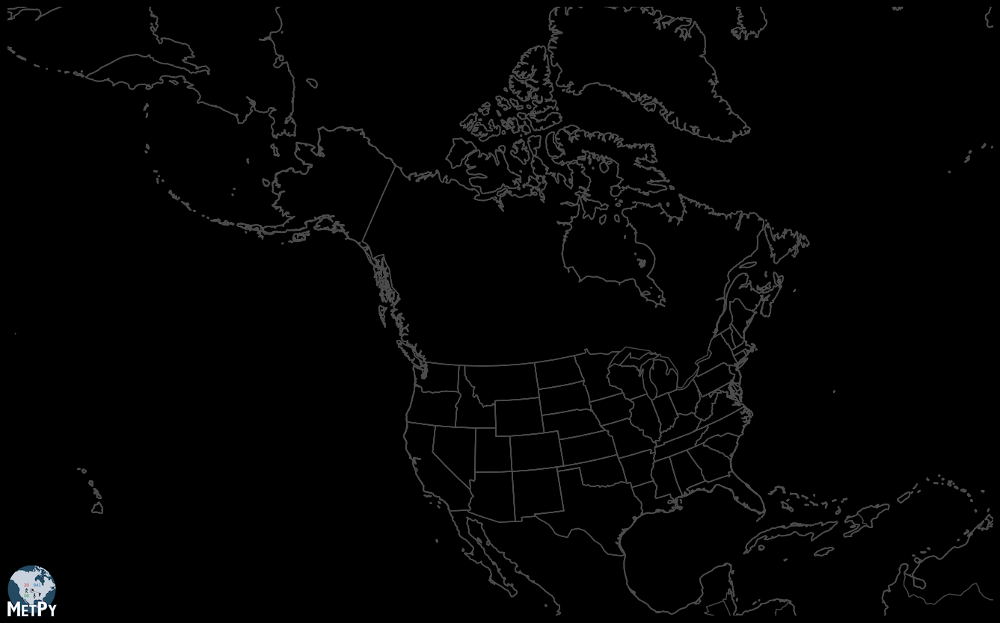

In [10]:
# create a figure and axes, add metpy logo, add some map features, set some parameters for the plot

# use a dark background for the plots
plt.style.use('dark_background')

fig = plt.figure(figsize=(17., 13.), edgecolor="white")
fig.patch.set_facecolor('black')
add_metpy_logo(fig, 5, 5, size='small')
ax = fig.add_subplot(1, 1, 1, projection=crs_rotated)
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=1.25, edgecolor="#4c4c4c")
ax.add_feature(cfeature.BORDERS, linewidth=1.00, edgecolor="#4c4c4c")
ax.add_feature(cfeature.STATES, linewidth=1.00, edgecolor="#4c4c4c")
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=1.25, edgecolor="#4c4c4c")
ax.add_feature(cfeature.STATES, linewidth=1.00, edgecolor="#4c4c4c")
ax.set_axis_off()

# set some earth longitude/latitude bounds for the plots
bounds = [(-170., -50., 20.5, 89.)]
ax.set_extent(*bounds, crs=ccrs.PlateCarree())


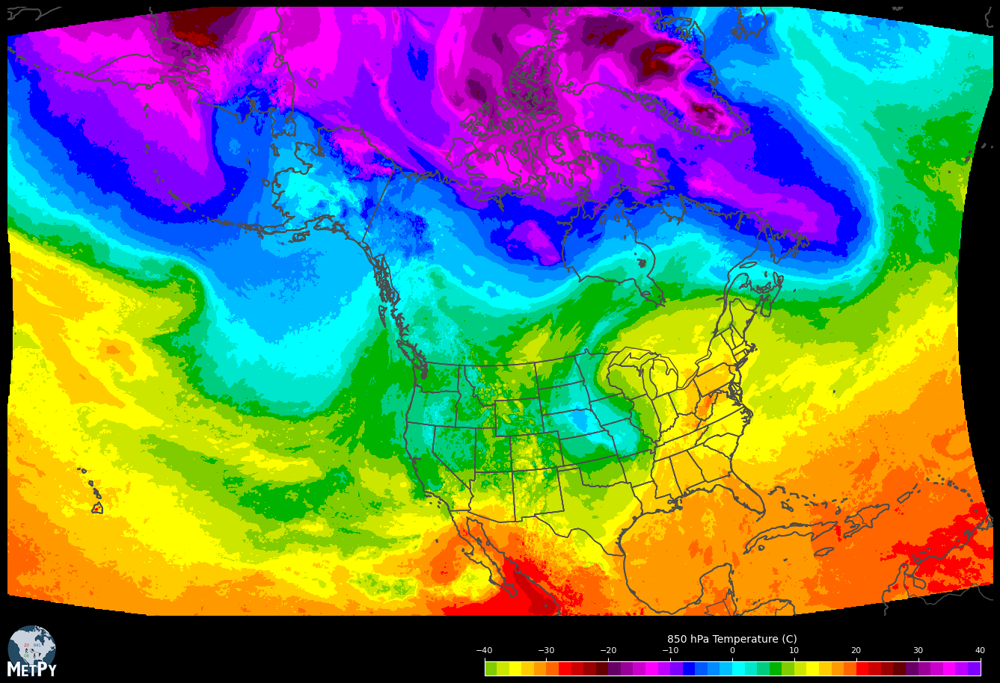

In [11]:
# Plot 850 hPa temps shaded using the colormap and levels defined above

levels, colors = colors_levels("850temps")
CS=ax.contourf(rlon,rlat,temperatures, \
            levels=levels,\
            colors=colors)

# Put a color bar at the bottom
cbaxes = fig.add_axes([0.5,0.12,0.39,0.015])
cbar = fig.colorbar(CS, cax=cbaxes, orientation='horizontal')

cbar.ax.tick_params(labelsize=8, colors='white')
cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.xaxis.set_label_position('top')
cbar.set_label('850 hPa Temperature (C)', color='white')

fig

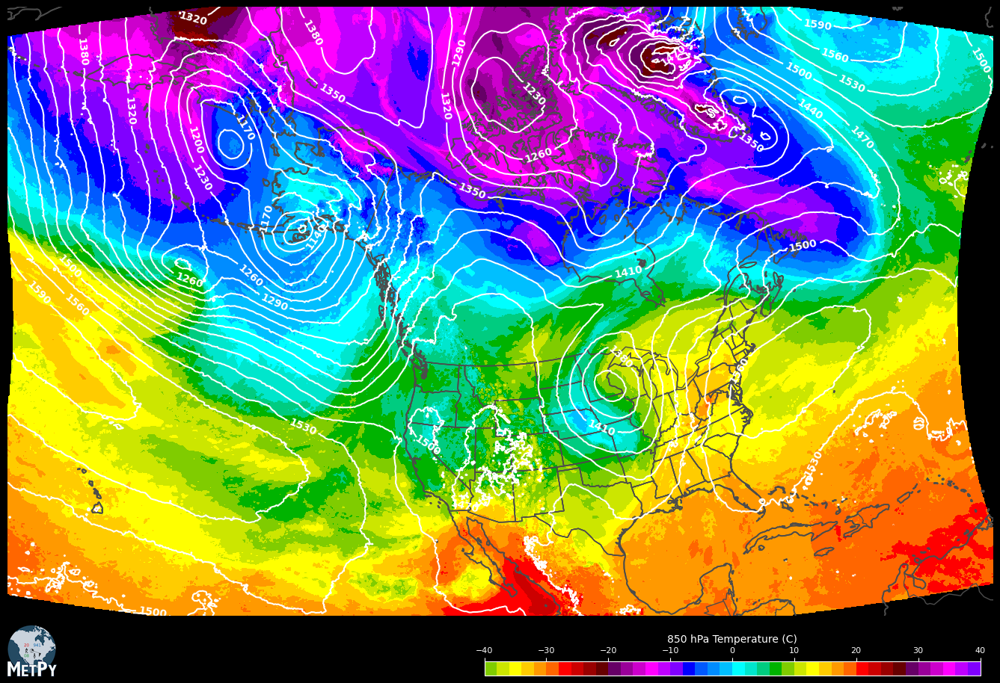

In [12]:
#Add 850 hPa heights, white conttours every 30 m, 
levels, colors = colors_levels("850heights")
hc = ax.contour(rlon,rlat,heights, \
                levels=levels, \
                colors=colors, linewidths = 1.5)
# Set the format and font size of the labels. Make them bold text also for readability.
hlabels=ax.clabel(hc, fmt='%1.0f', fontsize=10.0)
for label in hlabels:
    label.set_fontweight('bold')
fig

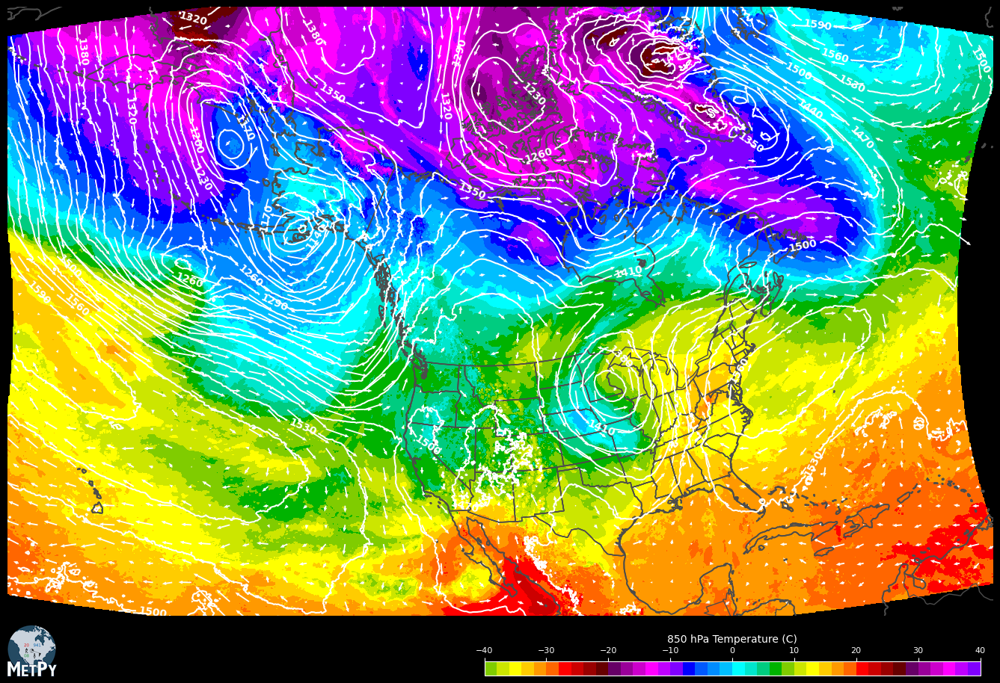

In [13]:
# Wind vectors here - use the thinned rlonvec/rlatvec instead of lon/lat

ax.quiver(rlonvec, rlatvec, u, v,\
            color="white", width=.0014, headwidth=2.5, headlength =3., headaxislength=3.0)
# Could plot wind barbs instead, in a grey color
#ax.barbs(rlonvec, rlatvec, u, v,\
#            color="#4c4c4c", length=6, pivot='middle') 
fig

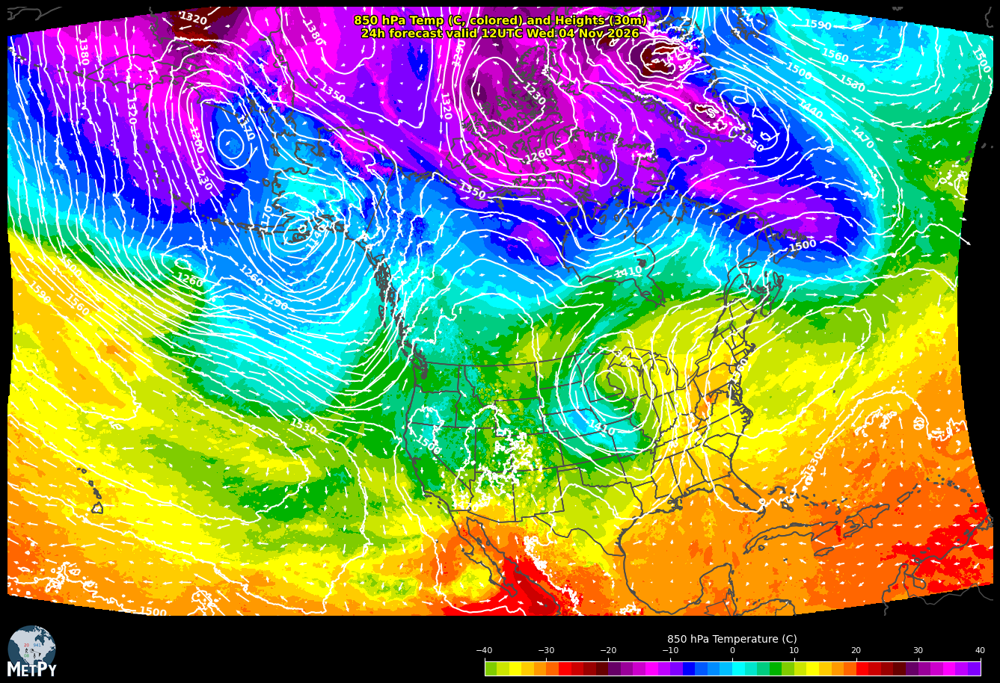

In [14]:
# Save figure
time_string = '850 hPa Temp (C, colored) and Heights (30m)\n'+str(hour)+'h forecast valid '\
              +fhour+'UTC '+fday_name+' '+fday+' '+fmonth_name+' '+fyear
#print(time_string)
text = ax.text(0.50, 0.95, time_string,
    horizontalalignment='center', transform = ax.transAxes,
    color='yellow', fontsize=11, weight='bold')
text.set_path_effects(outline_effect)
fig


In [15]:
fig.savefig("rrfs_c850_h"+shour+".png",  bbox_inches='tight', edgecolor="white", transparent=False, pad_inches=0.)
plt.close(fig)

# 500 hPa heights, absolute vorticity, wind vectors

In [16]:

# Specify that we want to use data at 500 hPa (50000 Pa)

avor_pres_val=50000.0
hght_pres_val=50000.0
u_pres_val=50000.0
v_pres_val=50000.0

# Grag the dimension variables for each of the variables that we want to plot
avor_kwdim=XR_DS['Absolute_vorticity_isobaric'].dims
hght_kwdim=XR_DS['Geopotential_height_isobaric'].dims
u_kwdim=XR_DS['u-component_of_wind_isobaric'].dims
v_kwdim=XR_DS['v-component_of_wind_isobaric'].dims

# Figure out what time and height (isobaric) keyword each variable is using. Turns out they are all the same in this case, but
# sometimes different variables use different names for these dimensions because they have different time intervals or
# different vertical coordinate systems or pressure levels.

xr_avor_da_time_keyword = str(avor_kwdim[0])
xr_hght_da_time_keyword = str(hght_kwdim[0])
xr_u_da_time_keyword = str(u_kwdim[0])
xr_v_da_time_keyword = str(v_kwdim[0])
xr_avor_da_isobaric_keyword = str(avor_kwdim[1])
xr_hght_da_isobaric_keyword = str(hght_kwdim[1])
xr_u_da_isobaric_keyword = str(u_kwdim[1])
xr_v_da_isobaric_keyword = str(v_kwdim[1])

# Figure out the index in the vertical direction for the level that we want.
avor_pres_index=np.where(XR_DS[xr_avor_da_isobaric_keyword].values == avor_pres_val)[0]
hght_pres_index=np.where(XR_DS[xr_hght_da_isobaric_keyword].values == hght_pres_val)[0]
u_pres_index=np.where(XR_DS[xr_u_da_isobaric_keyword].values == u_pres_val)[0]
v_pres_index=np.where(XR_DS[xr_v_da_isobaric_keyword].values == v_pres_val)[0]


# Pull in data arrays for each variable at the time and level that we want. Thin out the u/v components of the wind so there aren't so many wind vectors

xr_avor_da = XR_DS.Absolute_vorticity_isobaric.isel({xr_avor_da_time_keyword:xr_wantedtime}).isel({xr_avor_da_isobaric_keyword:avor_pres_index})
#xr_temp_da = XR_DS.Temperature_isobaric.isel({xr_temp_da_time_keyword:0}).isel({xr_temp_da_isobaric_keyword:temp_pres_index})
#xr_temp_da
xr_hght_da = XR_DS.Geopotential_height_isobaric.isel({xr_hght_da_time_keyword:xr_wantedtime}).isel({xr_hght_da_isobaric_keyword:hght_pres_index})
xr_hght_da
xr_u_da = XR_DS["u-component_of_wind_isobaric"].isel({xr_u_da_time_keyword:xr_wantedtime}).isel({xr_u_da_isobaric_keyword:u_pres_index}).thin(20)
xr_v_da = XR_DS["v-component_of_wind_isobaric"].isel({xr_v_da_time_keyword:xr_wantedtime}).isel({xr_v_da_isobaric_keyword:v_pres_index}).thin(20)



# Grab the lat/lon values in the rotated coordinate system. Again, thin out the lat/lon for the vector components.
rlat=XR_DS.rlat
rlon=XR_DS.rlon
rlonvec=XR_DS.rlon.thin(20)
rlatvec=XR_DS.rlat.thin(20)

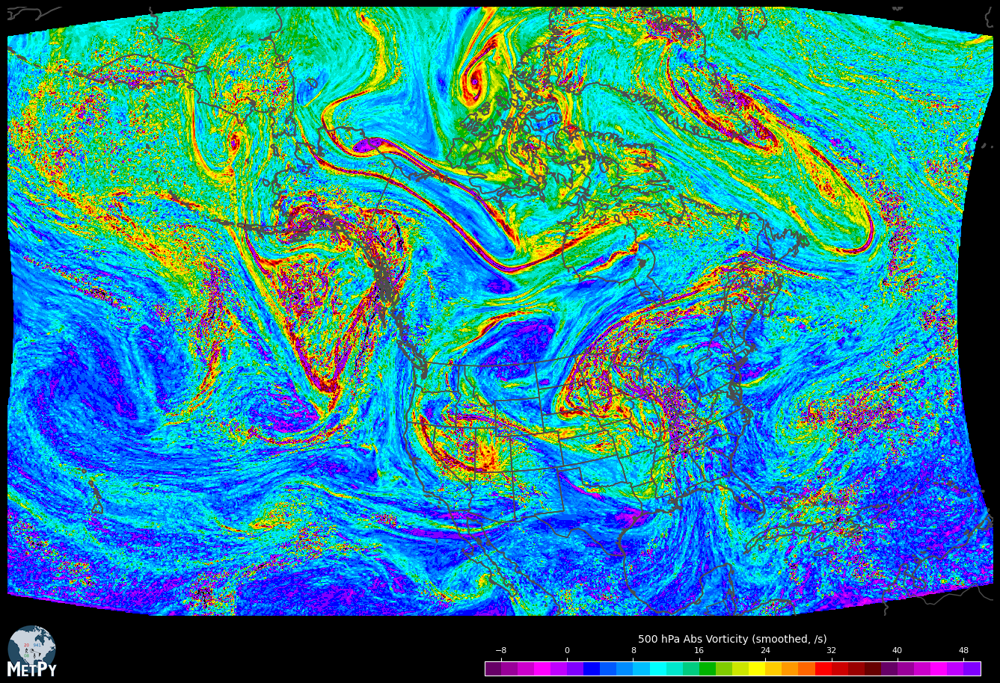

In [17]:
# convert vorticity to traditional units, winds to knots
avorts = xr_avor_da.values[0]*100000
heights = xr_hght_da.values[0]
u = xr_u_da.values[0]*1.94384
v = xr_v_da.values[0]*1.94384

fig2 = plt.figure(figsize=(17., 13.), edgecolor="white")
fig2.patch.set_facecolor('black')
add_metpy_logo(fig2, 5, 5, size='small')
ax2 = fig2.add_subplot(1, 1, 1, projection=crs_rotated)
#ax2 = fig2.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax2.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=1.25, edgecolor="#4c4c4c")
ax2.add_feature(cfeature.BORDERS, linewidth=1.00, edgecolor="#4c4c4c")
ax2.add_feature(cfeature.STATES, linewidth=1.00, edgecolor="#4c4c4c")
ax2.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=1.25, edgecolor="#4c4c4c")
ax2.add_feature(cfeature.STATES, linewidth=1.00, edgecolor="#4c4c4c")
ax2.set_axis_off()
ax2.set_extent(*bounds, crs=ccrs.PlateCarree())
ax2.set_axis_off()

levels, colors = colors_levels("500vort")
CS2=ax2.contourf(rlon,rlat,avorts, levels=levels, colors=colors)
#                            transform=ccrs.PlateCarree())
cbaxes2 = fig2.add_axes([0.5,0.12,0.39,0.015])
cbar2 = fig2.colorbar(CS2, cax=cbaxes2, orientation='horizontal')

cbar2.ax.tick_params(labelsize=8, colors='white')
cbar2.ax.xaxis.set_ticks_position('top')
cbar2.ax.xaxis.set_label_position('top')
cbar2.set_label('500 hPa Abs Vorticity (smoothed, /s)', color='white')



# That is really noisy - let's smooth it a bunch to make it more synoptic scale

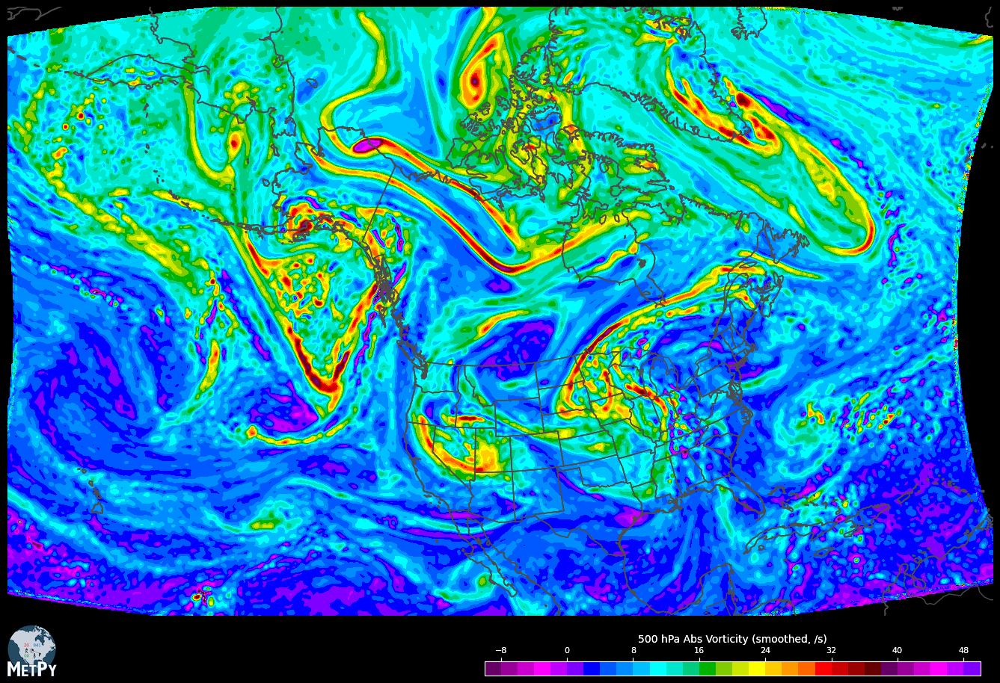

In [18]:
CS2=ax2.contourf(rlon,rlat,mpcalc.smooth_gaussian(avorts, 11), levels=levels, colors=colors)
#                            transform=ccrs.PlateCarree())
cbaxes2 = fig2.add_axes([0.5,0.12,0.39,0.015])
cbar2 = fig2.colorbar(CS2, cax=cbaxes2, orientation='horizontal')

cbar2.ax.tick_params(labelsize=8, colors='white')
cbar2.ax.xaxis.set_ticks_position('top')
cbar2.ax.xaxis.set_label_position('top')
cbar2.set_label('500 hPa Abs Vorticity (smoothed, /s)', color='white')
fig2

# add 500 hPa heights

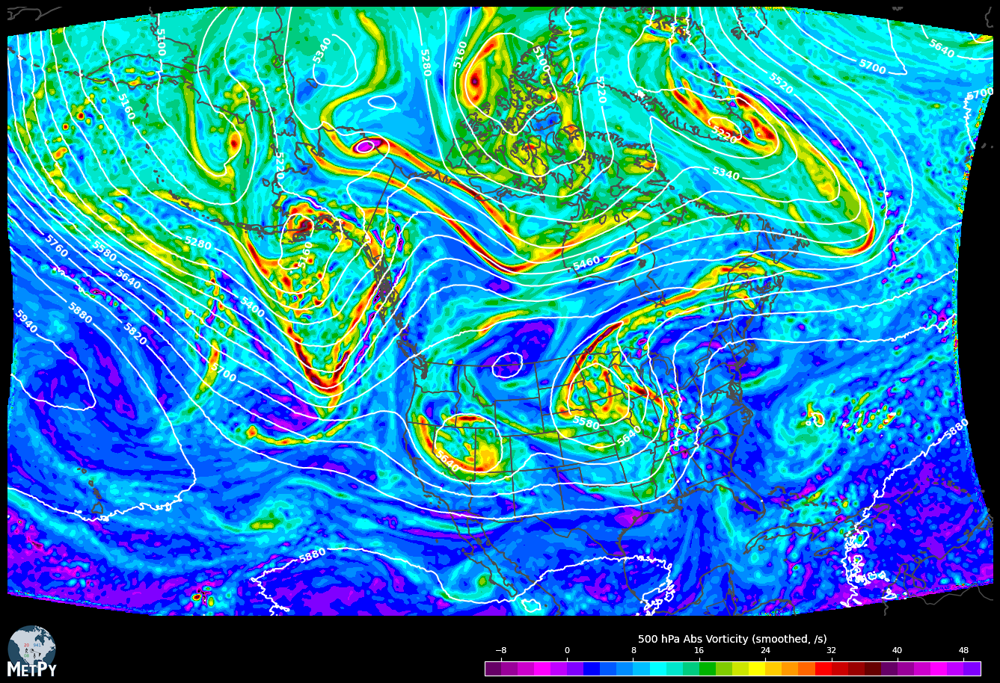

In [19]:
levels, colors = colors_levels("500heights")
hc2 = ax2.contour(rlon,rlat,heights, \
                levels=levels, \
                colors=colors, linewidths = 1.5)
#                plot_maxmin_points(ax2, rlon, rlat, heights, 'max', 75, symbol='H', color='white', transform=crs_rotated)
#                                   transform=ccrs.PlateCarree())
#                plot_maxmin_points(ax2, rlon, rlat, heights, 'min', 75, symbol='L', color='white', transform=crs_rotated)
#                                   transform=ccrs.PlateCarree())
hlabels=ax2.clabel(hc2, fmt='%1.0f', fontsize=10.0)
for label in hlabels:
    label.set_fontweight('bold')
fig2


# add wind vectors

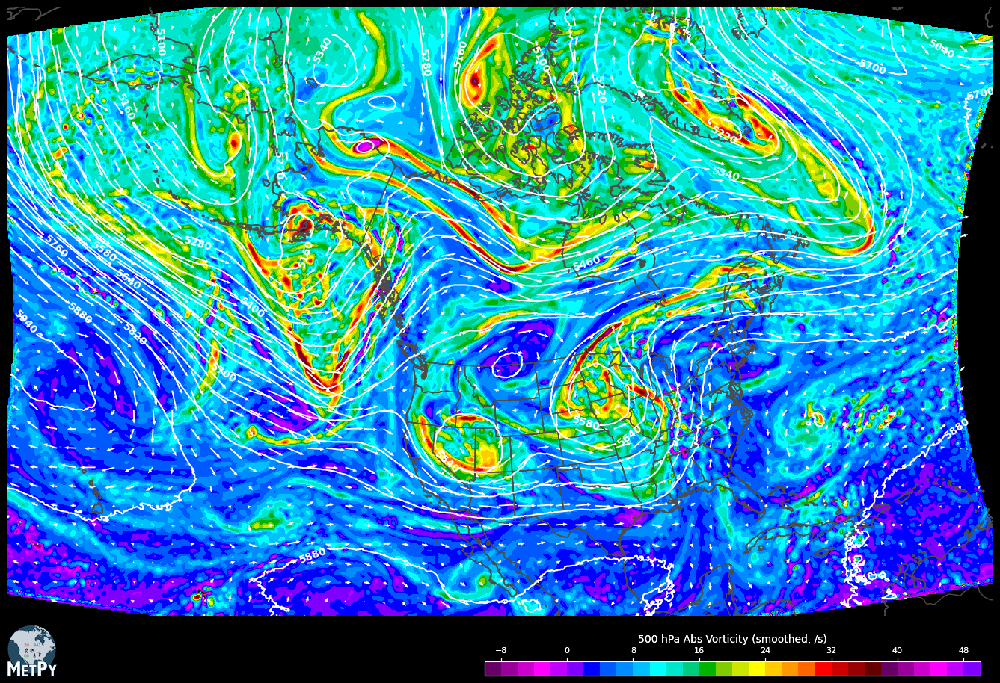

In [20]:
ax2.quiver(rlonvec, rlatvec, u, v,\
            color="white", width=.0014, headwidth=2.5, headlength =3., headaxislength=3.0)
fig2

500 hPa Abs. Vorticity (*10^5/s, colored) and Heights (60m)
24h forecast valid 12UTC Wed 04 Nov 2026


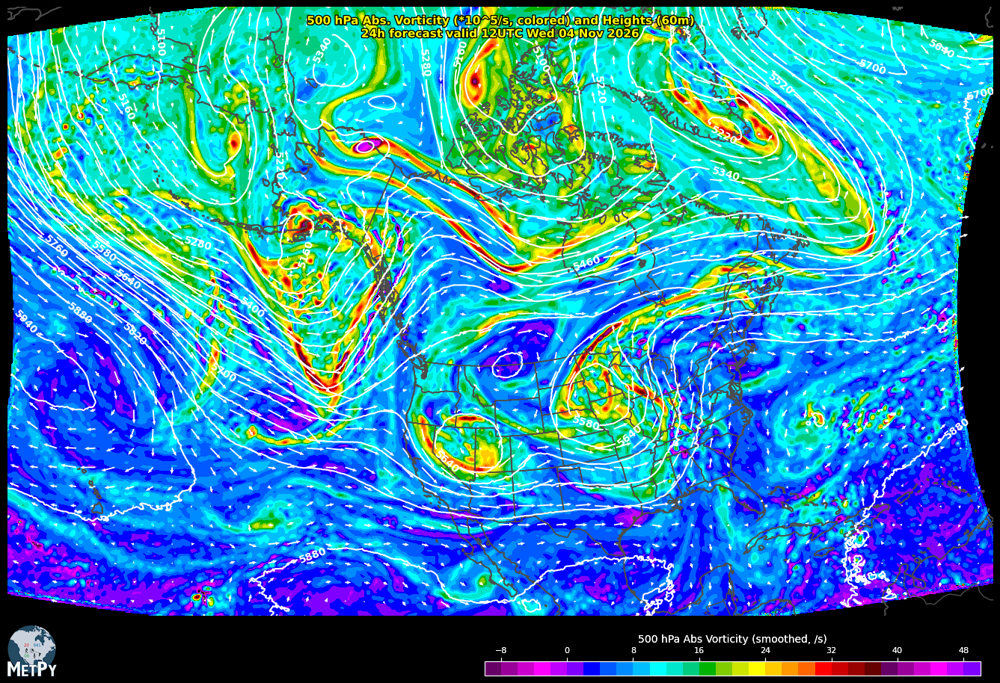

In [21]:
# Save fig
time_string = '500 hPa Abs. Vorticity (*10^5/s, colored) and Heights (60m)\n'+str(hour)+'h forecast valid '\
              +fhour+'UTC '+fday_name+' '+fday+' '+fmonth_name+' '+fyear

print(time_string)
text2 = ax2.text(0.50, 0.95, time_string,
    horizontalalignment='center', transform = ax2.transAxes,
    color='yellow', fontsize=11, weight='bold')
text2.set_path_effects(outline_effect)
fig2


In [22]:
fig2.savefig("rrfs_c500_h"+shour+".png", bbox_inches='tight', edgecolor="white", transparent=False, pad_inches=0.)
plt.close(fig2)